# Three-body posterior inference, results notebook

This notebook is the final, shareable summary of the project. It loads the
already-trained BayesFlow model and the held-out test data, and shows two
things: what the inferred posterior looks like for an easy and a hard
observation, and whether trajectories re-simulated from posterior samples
actually look like the real observation.

This notebook trains nothing. It only loads results that already exist on
disk (models/trained_model.keras and data/test.npz) and computes a small
number of new plots from them.

## Setup

This cell picks the torch backend for Keras (this has to happen before
bayesflow is imported, otherwise bayesflow can pick the wrong backend), then
picks the GPU if one is available and prints which device will be used, then
loads the trained model and the test dataset. Nothing is trained here; the
model file already contains the finished weights.

In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"

import sys
sys.path.insert(0, os.path.join(os.getcwd(), "code"))

import time
notebook_start_time = time.time()

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display
import keras
import bayesflow as bf

from device import get_device
from simulator import get_masses, EPSILON, integrate_system, total_energy
from diagnostics import sample_posterior, PARAM_NAMES

device = get_device()

model = keras.saving.load_model("models/trained_model.keras")
print("loaded models/trained_model.keras on", device)

data = np.load("data/test.npz")
theta = data["theta"].astype("float32")
obs_noisy = data["obs_noisy"].astype("float32")
t0 = data["t0"].astype("float32")
obs_times = data["obs_times"]
print("loaded", theta.shape[0], "test simulations")

INFO:bayesflow:Using backend 'torch'


When using torch backend, we need to disable autograd by default to avoid excessive memory usage. Use

with torch.enable_grad():
    ...

in contexts where you need gradients (e.g. custom training loops).


using GPU: NVIDIA GeForce RTX 5070 Ti Laptop GPU


loaded models/trained_model.keras on cuda
loaded 2000 test simulations


C:\projects\MscDSTU\2ndsemester\SBI\three_body_project\env_three_body\Lib\site-packages\keras\src\backend\torch\rnn.py:887: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1479.)
  outputs, h_n = torch._VF.gru(


## Choosing two example cases

Each test simulation observes the three-body system starting from a
different, randomly chosen offset t0 after the true initial time. A small t0
means the observation starts early, while the system is still close to its
known initial condition and only mildly affected by chaos. A large t0 means
the observation starts late, after the chaotic dynamics have had much more
time to amplify any uncertainty.

We pick the smallest and largest t0 in the test set as two representative
examples, and print their index in the test set and their t0 value, both in
raw simulation time units and in units of 1/lambda (the characteristic chaos
timescale; lambda_median = 0.7208 is the value measured earlier in the
project), which is the more physically meaningful scale.

In [2]:
lambda_median = 0.7208

small_index = int(np.argmin(t0))
large_index = int(np.argmax(t0))

cases = [
    ("small t0 (mildly chaotic)", small_index),
    ("large t0 (strongly chaotic)", large_index),
]

for label, index in cases:
    t0_val = float(t0[index])
    print(label)
    print("  test set index:", index)
    print("  t0 (raw time units):", t0_val)
    print("  t0 (units of 1/lambda):", t0_val * lambda_median)

small t0 (mildly chaotic)
  test set index: 1073
  t0 (raw time units): 0.0002825633273459971
  t0 (units of 1/lambda): 0.0002036716463509947
large t0 (strongly chaotic)
  test set index: 516
  t0 (raw time units): 8.322224617004395
  t0 (units of 1/lambda): 5.998659503936768


## Drawing posterior samples

For each of the two example cases, we ask the trained model for many samples
from its posterior over the 8 initial-condition parameters, using the noisy
observation and the known t0 as the two conditions the model was trained on.
This reuses the sample_posterior helper already written and tested in
code/diagnostics.py, including its GPU memory cleanup between calls, rather
than duplicating that logic here.

We draw more samples than diagnostics.py normally uses (2000 instead of 100)
because a smooth corner plot benefits from more points, and here this is only
needed for two cases instead of the whole test set.

In [3]:
NUM_DRAWS_FOR_PLOT = 2000

posterior_samples = {}
for label, index in cases:
    obs_window = obs_noisy[index:index + 1]
    t0_window = t0[index:index + 1].reshape(-1, 1)
    samples = sample_posterior(model, obs_window, t0_window, NUM_DRAWS_FOR_PLOT)
    posterior_samples[label] = samples[0]
    print(label, "drew", samples.shape[1], "posterior samples")

Summarizing:   0%|          | 0/1 [00:00<?, ?batch/s]

Sampling:   0%|          | 0/1 [00:00<?, ?batch/s]

small t0 (mildly chaotic) drew 2000 posterior samples


Summarizing:   0%|          | 0/1 [00:00<?, ?batch/s]

Sampling:   0%|          | 0/1 [00:00<?, ?batch/s]

large t0 (strongly chaotic) drew 2000 posterior samples


## Posterior corner plot

A corner plot shows every pair of the 8 parameters against each other: the
diagonal panels are histograms of one parameter on its own, and the
off-diagonal panels are scatter plots of one parameter against another. The
blue cloud is the mildly chaotic case's posterior, the red cloud is the
strongly chaotic case's posterior, and the dashed lines and x marks show the
true value used to simulate that case. Read the spread of each cloud as how
uncertain the model is about that parameter, and any separated blobs within
one cloud as genuine multiple explanations the model considers plausible.

The strongly chaotic case's posterior is expected to be much wider, and
possibly split into more than one cluster, than the mildly chaotic case's.
THIS IS THE CORRECT, HONEST RESULT FOR A CHAOTIC SYSTEM, NOT A FAILURE OF THE
MODEL: once enough time has passed, many different initial conditions can
lead to observations that look almost the same within the noise level, so the
honest answer really is a wide or multimodal range of possibilities, not a
single sharp number.

saved results/posterior_example.png


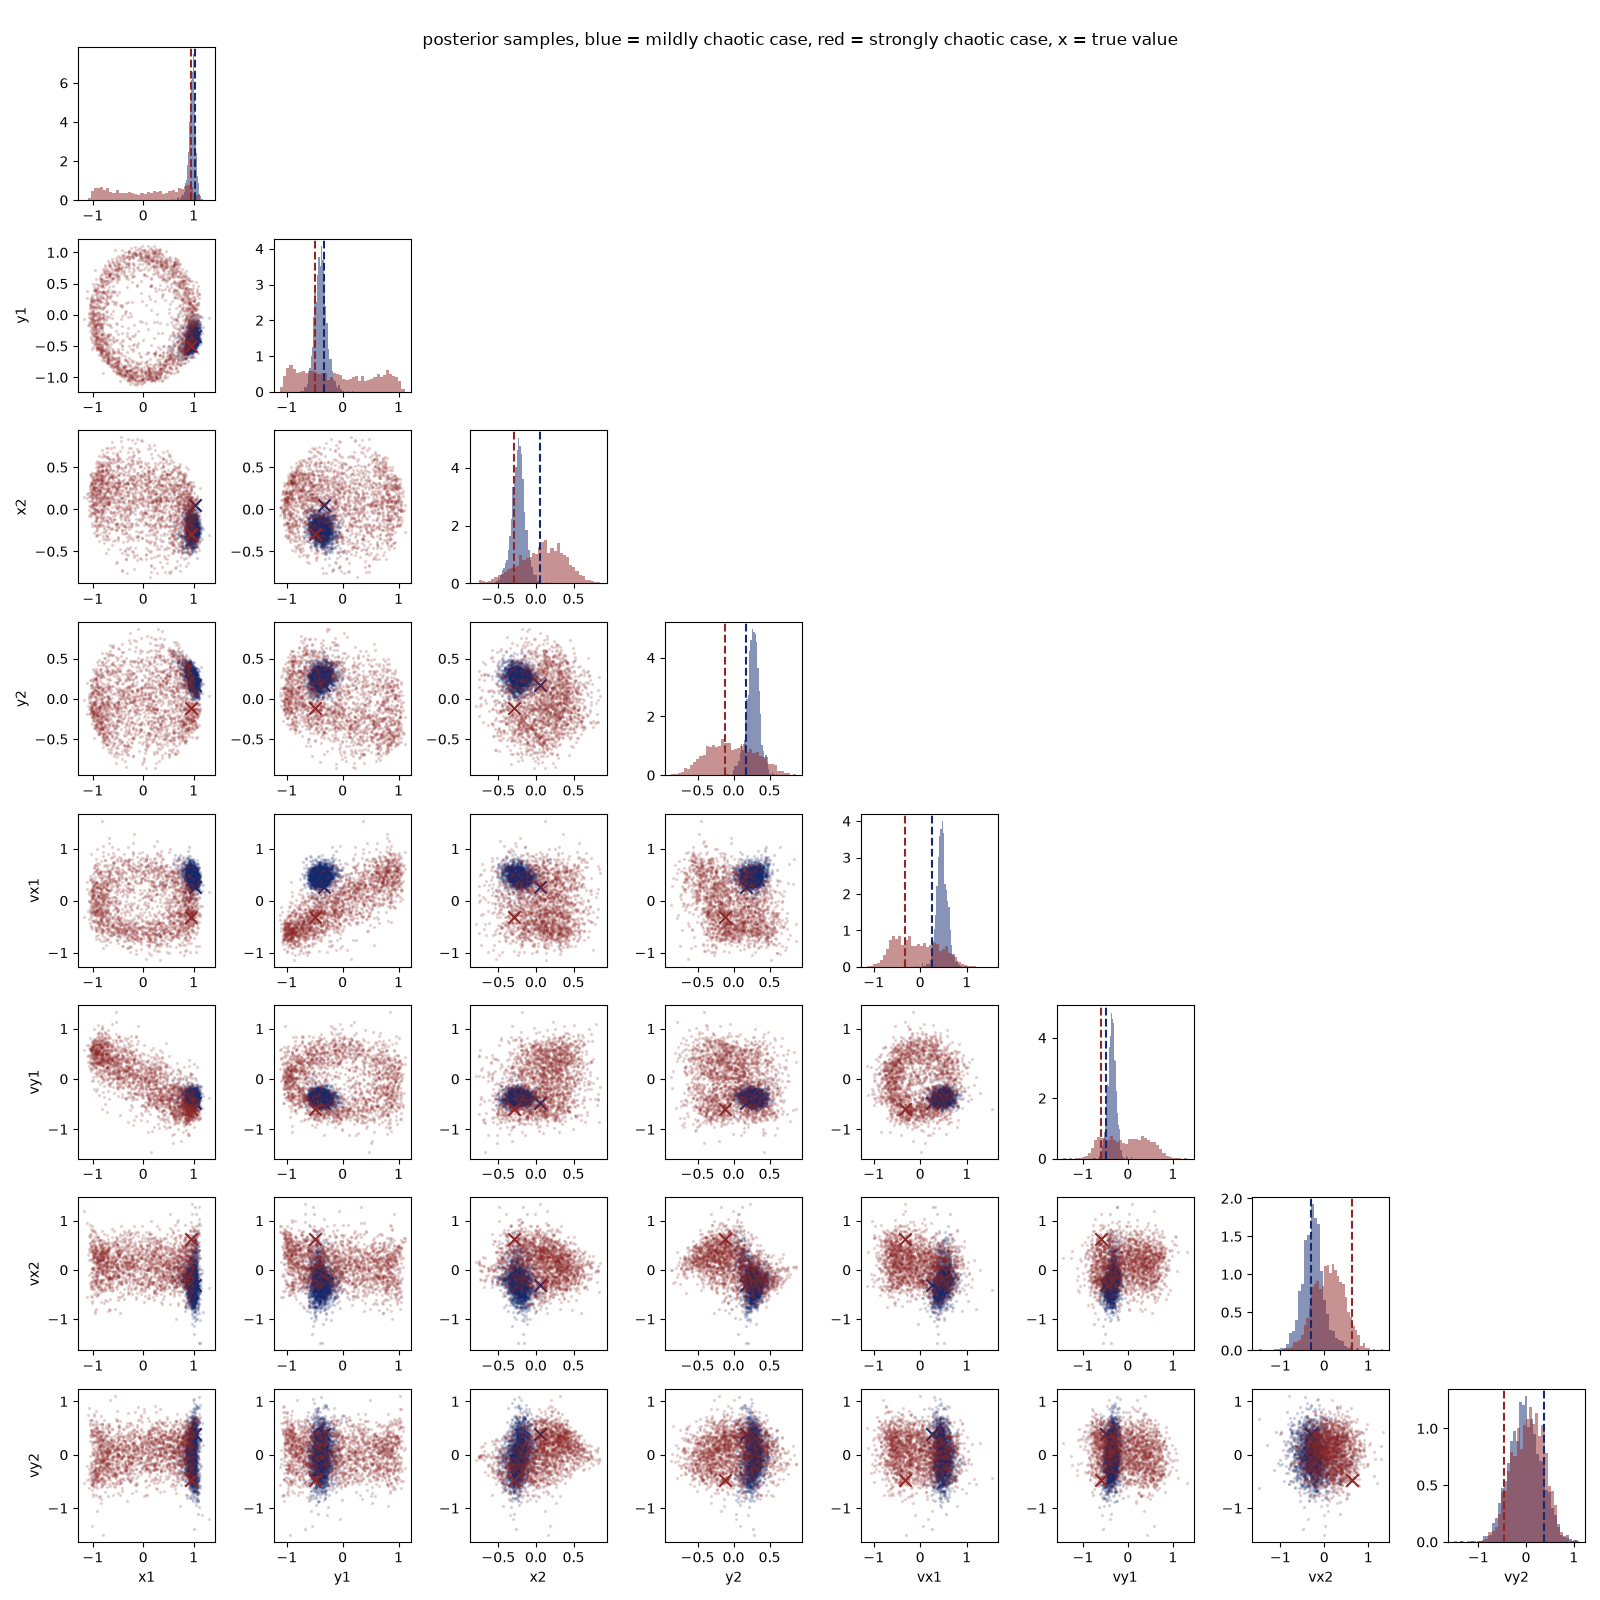

In [4]:
colors = {
    "small t0 (mildly chaotic)": "#132a70",
    "large t0 (strongly chaotic)": "#8f2727",
}

n_params = len(PARAM_NAMES)
fig, axes = plt.subplots(n_params, n_params, figsize=(16, 16))

for i in range(n_params):
    for j in range(n_params):
        ax = axes[i][j]
        if i == j:
            for label, index in cases:
                samples = posterior_samples[label]
                ax.hist(samples[:, i], bins=40, color=colors[label], alpha=0.5, density=True)
                ax.axvline(theta[index][i], color=colors[label], linestyle="--")
        elif i > j:
            for label, index in cases:
                samples = posterior_samples[label]
                ax.scatter(samples[:, j], samples[:, i], s=2, alpha=0.15, color=colors[label])
                ax.scatter([theta[index][j]], [theta[index][i]], color=colors[label], marker="x", s=80)
        else:
            ax.axis("off")
        if i == n_params - 1:
            ax.set_xlabel(PARAM_NAMES[j])
        if j == 0 and i > 0:
            ax.set_ylabel(PARAM_NAMES[i])

fig.suptitle(
    "posterior samples, blue = mildly chaotic case, red = strongly chaotic case, x = true value"
)
fig.tight_layout()
fig.savefig("results/posterior_example.png")
plt.close(fig)
print("saved results/posterior_example.png")
display(Image(filename="results/posterior_example.png"))

## Posterior predictive check

This check asks a different question: if we take some of the model's
posterior samples as if they were the true initial condition, physically
simulate them forward with the same integrator used to build the dataset
(code/simulator.py), and look at the resulting trajectory, does it look like
the actual noisy observation?

For each case we re-simulate NUM_PREDICTIVE_DRAWS posterior draws. Each
re-simulated trajectory is split at t0, the start of the observation window:
the part before t0 (dashed, faint) is un-observed history, shown only for
context, since nothing constrains it; the part from t0 to t0 + T (solid,
darker) is the actual observation window, the part that is meant to be
compared against the noisy observation (solid dots with a black outline).

Every re-simulated trajectory's energy drift is measured, the same way it was
measured when the training and test datasets were built, and reported below
the plot: the largest drift seen over all draws in each case, and how many
draws exceeded the 1e-8 limit used during dataset generation. That limit was
designed for PRIOR draws, which are rejection-filtered so that any trajectory
coming too close to a collision or escaping the system is thrown out before
it ever reaches the dataset. Posterior draws are not filtered that way: the
posterior is free to place some probability mass on initial conditions that
lead to a near-collision, and the integrator genuinely strains through those
close encounters, elevating the measured energy drift. An occasional small
exceedance here is expected, and is itself information about the posterior
(it can point at parameter combinations the model considers plausible but
that are dynamically close to the accept or reject boundary used to build the
training data), not a sign that something is broken. Only a real integrator
failure is treated as an error.

Good visual agreement in the solid, observed segment shows the posterior
samples are dynamically consistent with producing an observation like the one
we actually saw. IT DOES NOT BY ITSELF PROVE those samples are close to the
true initial condition, because in a chaotic system, different initial
conditions can produce visually similar noisy observations. The calibration
checks in results/calibration_ecdf.png and results/chaos_summary.png are the
rigorous test of correctness; this plot is a sanity check, not a calibration
proof.

small t0 (mildly chaotic) max energy drift over 30 draws: 5.5405675136276915e-09
small t0 (mildly chaotic) draws exceeding 1e-08 : 0 out of 30
small t0 (mildly chaotic) draws escaping past radius 10.0 : 0 out of 30


large t0 (strongly chaotic) max energy drift over 30 draws: 2.021464953332018e-08
large t0 (strongly chaotic) draws exceeding 1e-08 : 2 out of 30
large t0 (strongly chaotic) draws escaping past radius 10.0 : 0 out of 30


saved results/posterior_predictive.png


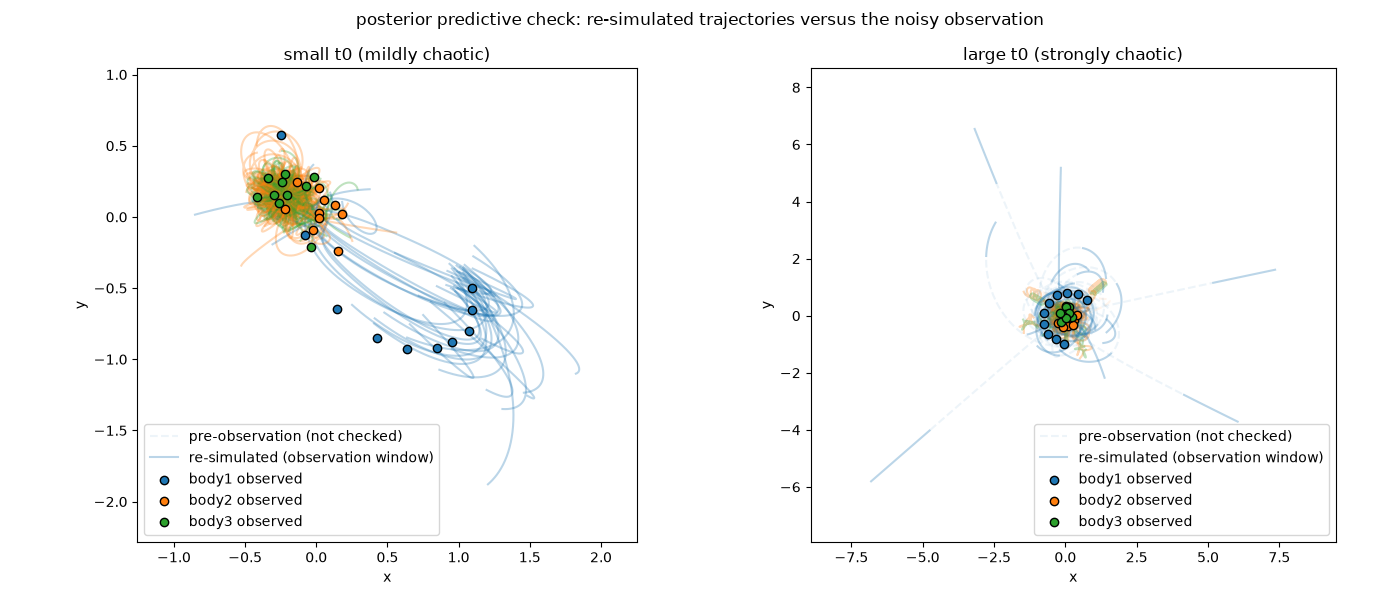

total notebook runtime in seconds: 20.259889602661133


In [5]:
NUM_PREDICTIVE_DRAWS = 30
ENERGY_DRIFT_LIMIT = 1e-8
ESCAPE_RADIUS = 10.0
masses = get_masses()
T = float(obs_times[-1])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for panel_index, (label, index) in enumerate(cases):
    ax = axes[panel_index]
    t0_val = float(t0[index])
    span_times = np.linspace(0.0, t0_val + T, 300)
    pre_mask = span_times <= t0_val
    obs_mask = span_times >= t0_val

    draws = posterior_samples[label][:NUM_PREDICTIVE_DRAWS]
    max_drift_all = []
    n_exceed = 0
    n_escaped = 0
    x_focus = []
    y_focus = []

    for draw_index, draw in enumerate(draws):
        r1 = draw[0:2]
        r2 = draw[2:4]
        v1 = draw[4:6]
        v2 = draw[6:8]
        r3 = -(masses[0] * r1 + masses[1] * r2) / masses[2]
        v3 = -(masses[0] * v1 + masses[1] * v2) / masses[2]
        state0 = np.zeros(12)
        state0[0:2] = r1
        state0[2:4] = r2
        state0[4:6] = r3
        state0[6:8] = v1
        state0[8:10] = v2
        state0[10:12] = v3

        trajectory, success = integrate_system(state0, span_times, masses, EPSILON)
        if not success:
            raise RuntimeError("re-simulation failed for a posterior draw in case " + label)

        energy0 = total_energy(trajectory[0], masses, EPSILON)
        max_drift = 0.0
        for row in trajectory:
            e = total_energy(row, masses, EPSILON)
            drift = abs(e - energy0) / abs(energy0)
            if drift > max_drift:
                max_drift = drift
        max_drift_all.append(max_drift)
        if max_drift > ENERGY_DRIFT_LIMIT:
            n_exceed = n_exceed + 1

        if draw_index == 0:
            pre_label = "pre-observation (not checked)"
            obs_label = "re-simulated (observation window)"
        else:
            pre_label = None
            obs_label = None

        ax.plot(trajectory[pre_mask, 0], trajectory[pre_mask, 1], color="tab:blue", alpha=0.08, linestyle="--", label=pre_label)
        ax.plot(trajectory[pre_mask, 2], trajectory[pre_mask, 3], color="tab:orange", alpha=0.08, linestyle="--")
        ax.plot(trajectory[pre_mask, 4], trajectory[pre_mask, 5], color="tab:green", alpha=0.08, linestyle="--")

        ax.plot(trajectory[obs_mask, 0], trajectory[obs_mask, 1], color="tab:blue", alpha=0.3, label=obs_label)
        ax.plot(trajectory[obs_mask, 2], trajectory[obs_mask, 3], color="tab:orange", alpha=0.3)
        ax.plot(trajectory[obs_mask, 4], trajectory[obs_mask, 5], color="tab:green", alpha=0.3)

        # only the observation window sets the plot limits, the dashed history can run off the edge
        for body in range(3):
            x_focus.extend(trajectory[obs_mask, 2 * body])
            y_focus.extend(trajectory[obs_mask, 2 * body + 1])

    print(label, "max energy drift over", len(draws), "draws:", max(max_drift_all))
    print(label, "draws exceeding", ENERGY_DRIFT_LIMIT, ":", n_exceed, "out of", len(draws))
    print(label, "draws escaping past radius", ESCAPE_RADIUS, ":", n_escaped, "out of", len(draws))

    observed = obs_noisy[index]
    ax.scatter(observed[:, 0], observed[:, 1], color="tab:blue", edgecolor="black", zorder=5, label="body1 observed")
    ax.scatter(observed[:, 2], observed[:, 3], color="tab:orange", edgecolor="black", zorder=5, label="body2 observed")
    ax.scatter(observed[:, 4], observed[:, 5], color="tab:green", edgecolor="black", zorder=5, label="body3 observed")

    max_radius = 0.0
    for row in trajectory[obs_mask]:
        for body in range(3):
            r = np.sqrt(row[2 * body] ** 2 + row[2 * body + 1] ** 2)
            if r > max_radius:
                max_radius = r
    if max_radius > ESCAPE_RADIUS:
        n_escaped = n_escaped + 1

    ax.set_title(label)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.legend()

    ax.set_aspect("equal")
    pad = 0.15 * max(max(x_focus) - min(x_focus), max(y_focus) - min(y_focus))
    ax.set_xlim(min(x_focus) - pad, max(x_focus) + pad)
    ax.set_ylim(min(y_focus) - pad, max(y_focus) + pad)

fig.suptitle("posterior predictive check: re-simulated trajectories versus the noisy observation")
fig.tight_layout()
fig.savefig("results/posterior_predictive.png")
plt.close(fig)
print("saved results/posterior_predictive.png")
display(Image(filename="results/posterior_predictive.png"))

notebook_elapsed = time.time() - notebook_start_time
print("total notebook runtime in seconds:", notebook_elapsed)

## Summary

The two examples in this notebook put a concrete, visual face on the project's
central finding.

The mildly chaotic case (small t0, observation window starting essentially at
t = 0) gives a tight, close to single peaked posterior that recovers the true
initial condition closely. The strongly chaotic case (large t0, window starting
about 6 Lyapunov times later) gives a much wider posterior with clear
non-Gaussian structure in several parameters. This is not the model failing. It
is the model correctly reporting that, once chaos has had time to amplify small
differences, many different initial conditions produce observations that look
almost the same within the noise level, so the honest answer is a broad range of
possibilities rather than a single sharp number. This matches the project's main
diagnostic (results/chaos_summary.png), where posterior contraction fades from
about 0.76 to about 0.26 as the observation window starts later, while the
calibration error stays low and flat throughout.

The posterior predictive check tells a more nuanced story, and it is worth
stating honestly. In both cases the re-simulated trajectories pass through the
observed points, so the posterior draws are dynamically consistent with the data
we actually saw. But in the strongly chaotic case the same trajectories diverge
dramatically outside the observed window, and a few of the posterior draws land
on near-collision configurations that the prior's rejection sampling would have
thrown out during dataset generation. These show up as energy drift above the
1e-8 limit used to accept training simulations. The exact number of such draws
varies from run to run, because posterior sampling is stochastic, but the effect
is consistently worse at large t0 than at small t0, which is what a wider
posterior spilling further past the prior's support would predict.

The honest reading is therefore two sided. The posterior's per-parameter
marginals are well calibrated: the rank statistics behave correctly within each
lateness bin, and the width of the posterior tracks how much information the
observation actually carries. But the posterior is a smooth density that does not
know about the prior's hard accept and reject boundary, so it places some
probability mass on initial conditions the effective prior excludes. Getting the
marginal widths right is not the same as getting the joint structure right, and
in a chaotic system the set of initial conditions compatible with an observation
is thin and intricate, not a smooth blob.

That gap is a real limitation of this method, not an artifact of this notebook,
and it is recorded as such rather than hidden. The wide posterior is the correct
answer. The occasional out-of-support draw is the price of representing it with a
smooth normalizing flow.